In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering

from scipy.cluster.hierarchy import dendrogram, linkage

In [2]:
df = pd.read_csv("c:/Users/Janvi/Downloads/sales_data_sample.csv", encoding='latin1')

In [3]:
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nDataset Information:")
print(df.info())

   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           NaN            NYC    NY   
1             59 rue de l'Abbaye           NaN

In [4]:
# Select numerical features
features = [
    'QUANTITYORDERED',
    'PRICEEACH',
    'SALES',
    'MSRP'
]

X = df[features].copy()

# Remove missing and infinite values
X = X.replace([np.inf, -np.inf], np.nan)

X = X.dropna()

print("Preprocessed Data:")
print(X.head())

print("\nShape:")
print(X.shape)

Preprocessed Data:
   QUANTITYORDERED  PRICEEACH    SALES  MSRP
0               30      95.70  2871.00    95
1               34      81.35  2765.90    95
2               41      94.74  3884.34    95
3               45      83.26  3746.70    95
4               49     100.00  5205.27    95

Shape:
(2823, 4)


In [5]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Feature scaling completed.")

Feature scaling completed.


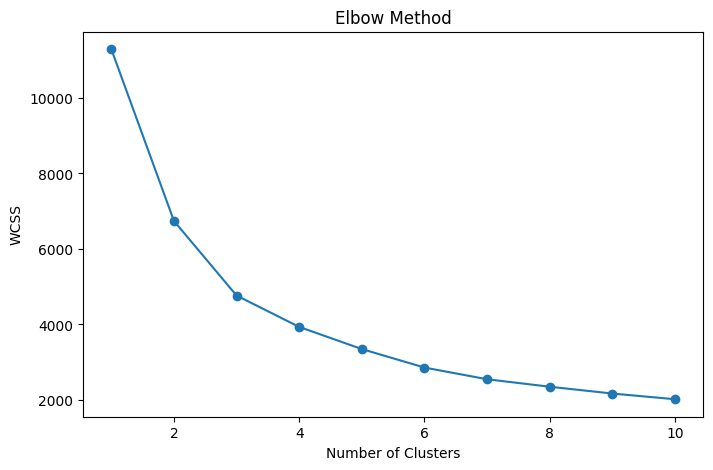

In [6]:
wcss = []

for i in range(1, 11):

    kmeans = KMeans(
        n_clusters=i,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    wcss.append(kmeans.inertia_)


plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 11),
    wcss,
    marker='o'
)

plt.xlabel("Number of Clusters")

plt.ylabel("WCSS")

plt.title("Elbow Method")

plt.show()

In [7]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X_scaled)

X['KMeans_Cluster'] = kmeans_labels

print("K-Means Clustering Results:")

print(X.head())

print("\nCluster Counts:")

print(X['KMeans_Cluster'].value_counts().sort_index())

K-Means Clustering Results:
   QUANTITYORDERED  PRICEEACH    SALES  MSRP  KMeans_Cluster
0               30      95.70  2871.00    95               2
1               34      81.35  2765.90    95               2
2               41      94.74  3884.34    95               1
3               45      83.26  3746.70    95               1
4               49     100.00  5205.27    95               1

Cluster Counts:
KMeans_Cluster
0    975
1    852
2    996
Name: count, dtype: int64


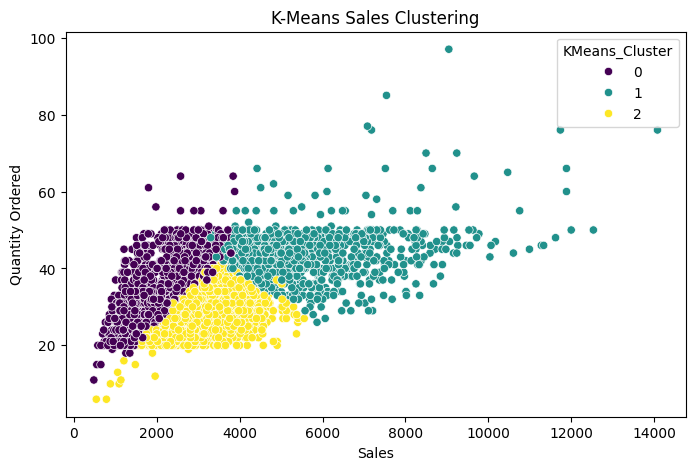

In [8]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=X['SALES'],
    y=X['QUANTITYORDERED'],
    hue=X['KMeans_Cluster'],
    palette='viridis'
)

plt.title("K-Means Sales Clustering")

plt.xlabel("Sales")

plt.ylabel("Quantity Ordered")

plt.show()

In [9]:
# Create hierarchical clustering model

hc = AgglomerativeClustering(
    n_clusters=3,
    linkage='ward'
)

hierarchical_labels = hc.fit_predict(X_scaled)

X['Hierarchical_Cluster'] = hierarchical_labels

print("Hierarchical Clustering Results:")

print(X.head())

print("\nCluster Counts:")

print(
    X['Hierarchical_Cluster']
    .value_counts()
    .sort_index()
)

Hierarchical Clustering Results:
   QUANTITYORDERED  PRICEEACH    SALES  MSRP  KMeans_Cluster  \
0               30      95.70  2871.00    95               2   
1               34      81.35  2765.90    95               2   
2               41      94.74  3884.34    95               1   
3               45      83.26  3746.70    95               1   
4               49     100.00  5205.27    95               1   

   Hierarchical_Cluster  
0                     2  
1                     2  
2                     0  
3                     0  
4                     1  

Cluster Counts:
Hierarchical_Cluster
0    1204
1     934
2     685
Name: count, dtype: int64


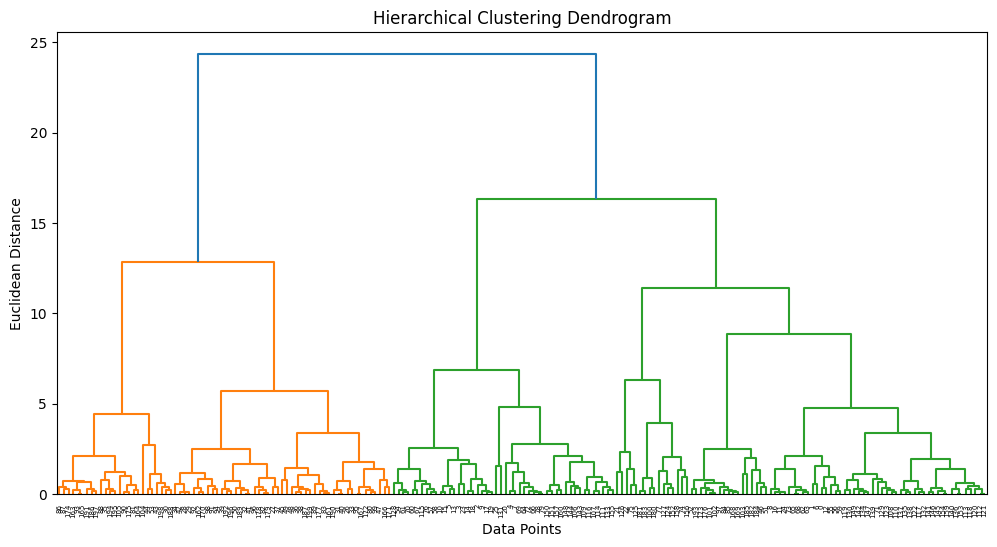

In [10]:
# Use a smaller sample to avoid excessive memory usage

sample_size = min(200, len(X_scaled))

Z = linkage(
    X_scaled[:sample_size],
    method='ward'
)

plt.figure(figsize=(12, 6))

dendrogram(Z)

plt.title("Hierarchical Clustering Dendrogram")

plt.xlabel("Data Points")

plt.ylabel("Euclidean Distance")

plt.show()

In [11]:
comparison = pd.DataFrame({
    'KMeans Cluster': kmeans_labels,
    'Hierarchical Cluster': hierarchical_labels
})

print(comparison.head(10))

print("\nK-Means Cluster Count:")
print(pd.Series(kmeans_labels).value_counts().sort_index())

print("\nHierarchical Cluster Count:")
print(pd.Series(hierarchical_labels).value_counts().sort_index())

   KMeans Cluster  Hierarchical Cluster
0               2                     2
1               2                     2
2               1                     0
3               1                     0
4               1                     1
5               2                     0
6               2                     2
7               1                     1
8               2                     2
9               1                     1

K-Means Cluster Count:
0    975
1    852
2    996
Name: count, dtype: int64

Hierarchical Cluster Count:
0    1204
1     934
2     685
Name: count, dtype: int64
